# 03 – Point-spread ratings by ridge regression

Phase 3 model: regress each game's home margin on team indicators.

$$	ext{margin}_g = h \cdot 	ext{home}_g + \sum_t eta_t x_{g,t} + arepsilon_g$$

$x_{g,t}$ is +1 for the home team, −1 for the away team, 0 otherwise. Each $eta_t$ is a rating in points versus an average team; $h$ is home-field advantage.

**How this differs from Elo.** Elo updates once per game and never revisits old results. This model re-solves every game so far each week, so strength of schedule flows both ways. Ridge shrinks each coefficient toward a prior mean (last season's rating, partly reverted to average): it is the Bayesian posterior mean with $lpha = \sigma^2_arepsilon / 	au^2_eta$.

All code lives in `src/football_model/spread.py`; tuning in `scripts/tune_spread.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from football_model import clean, config, elo, evaluate, spread

games = clean.load_games_table()
games = games[games["season"] <= config.TEST_SEASON].reset_index(drop=True)
params = spread.SpreadParams()
params

SpreadParams(alpha=3.0, revert=0.1, margin_cap=None, half_life_weeks=None)

## 1. The design matrix

Week 1 of 2024, a few rows. Each row has exactly one +1 and one −1 among the team columns; `home_field` is 0 at neutral sites.

In [2]:
wk = games[(games["season"] == 2024) & (games["week"] == 1)]
teams = sorted(set(wk["home_team"]) | set(wk["away_team"]))
X, y = spread.design_matrix(wk, teams)
example = X.iloc[:5]
shown = ["home_field"] + [t for t in teams if (example[t] != 0).any()]
pd.concat([wk[["home_team", "away_team", "neutral_site"]].iloc[:5], example[shown], y.iloc[:5]], axis=1)

,home_team,away_team,neutral_site,home_field,FCS,Florida State,Georgia Tech,Hawai'i,Nevada,New Mexico,Rutgers,SMU,margin
8520,Georgia Tech,Florida State,True,0.0,0.0,-1.0,1.0,0.0,0.0,0.0,0.0,0.0,3.0
8521,New Mexico,FCS,False,1.0,-1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-4.0
8522,Nevada,SMU,False,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-1.0,-5.0
8523,Hawai'i,FCS,False,1.0,-1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,21.0
8524,Rutgers,FCS,False,1.0,-1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,37.0


## 2. Coefficients: one fit, no prior

Fit all of 2024 with a zero prior (plain ridge toward 0) to see the raw coefficient table and residuals.

In [3]:
s24 = games[games["season"] == 2024]
teams24 = sorted(set(s24["home_team"]) | set(s24["away_team"]))
zero = pd.Series(0.0, index=["home_field", *teams24])
coef = spread.fit_ratings(s24, zero, spread.SpreadParams(alpha=3.0))
print(f"home field: {coef['home_field']:.2f} points")
coef.drop("home_field").sort_values(ascending=False).head(10).round(1)

home field: 3.92 points


Ohio State    23.5
Notre Dame    21.4
Ole Miss      19.6
Texas         19.3
Indiana       19.2
Penn State    16.5
Alabama       16.1
Tennessee     16.1
Miami         14.5
Georgia       14.4
dtype: float64

in-sample residual SD: 13.9 points


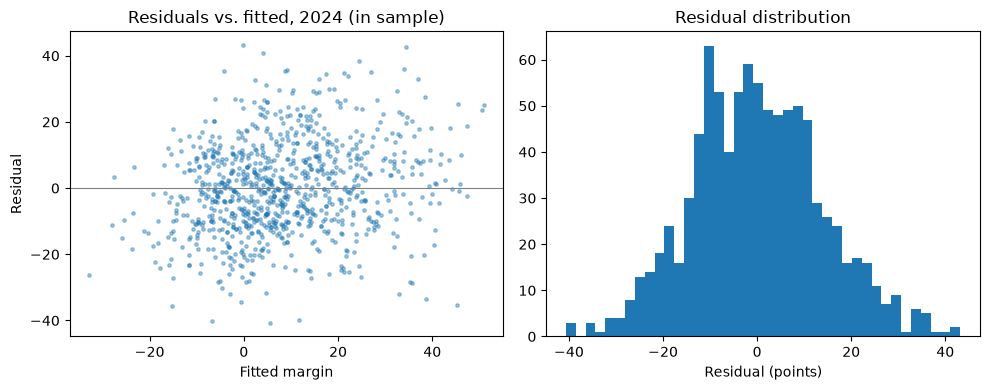

In [4]:
X24, y24 = spread.design_matrix(s24, teams24)
fitted = X24.to_numpy() @ coef.to_numpy()
resid = y24 - fitted
print(f"in-sample residual SD: {resid.std():.1f} points")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(fitted, resid, s=6, alpha=0.4)
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set(xlabel="Fitted margin", ylabel="Residual", title="Residuals vs. fitted, 2024 (in sample)")
axes[1].hist(resid, bins=40)
axes[1].set(xlabel="Residual (points)", title="Residual distribution")
plt.tight_layout()

## 3. The ridge path: how alpha shrinks ratings

Small alpha ≈ OLS (ratings spread out, noisy for teams with few games); large alpha pulls every rating toward the prior mean (0 here). Tuned alpha is 3.

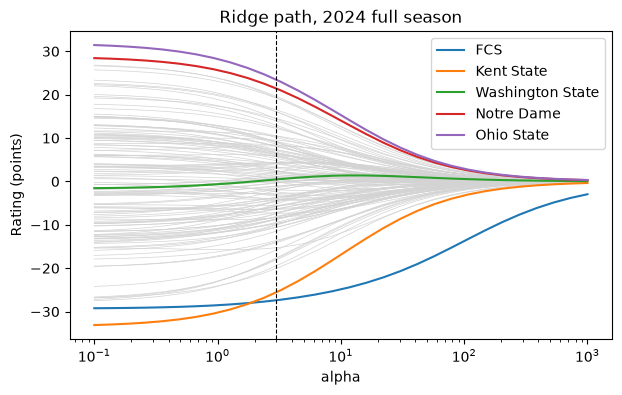

In [5]:
alphas = np.logspace(-1, 3, 30)
path = pd.DataFrame(
    {a: spread.fit_ratings(s24, zero, spread.SpreadParams(alpha=a)).drop("home_field") for a in alphas}
).T
top = coef.drop("home_field").sort_values().index[[0, 1, len(teams24) // 2, -2, -1]]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(path.index, path, color="lightgray", linewidth=0.5)
for team in top:
    ax.plot(path.index, path[team], label=team)
ax.axvline(params.alpha, color="black", linestyle="--", linewidth=0.8)
ax.set(xscale="log", xlabel="alpha", ylabel="Rating (points)", title="Ridge path, 2024 full season")
ax.legend()

## 4. Walk-forward predictions vs. Elo and the market

Every prediction uses only games before that week (plus last season's prior). 2014 is burn-in; scores are on the tuning seasons (2015–2024, excl. 2020).

In [6]:
pred = spread.run_spread(games, params)
rated = elo.predict(games, elo.EloParams(), config.TUNING_SEASONS)
pred = pred.merge(rated[["game_id", "elo_spread"]], on="game_id")
evaluate.score_by_week(pred, ["spread_pred", "elo_spread"], config.TUNING_SEASONS).round(3)

,games,spread_pred,elo_spread,market
bucket,,,,
weeks 1-4,2612,14.067,14.680,12.293
weeks 5-8,2000,13.068,13.332,12.224
weeks 9+,2930,12.862,13.146,12.376
postseason,369,13.759,13.829,12.918
all,7911,13.354,13.731,12.335


[Text(0.5, 0, 'Week'), Text(0, 0.5, 'MAE (points)')]

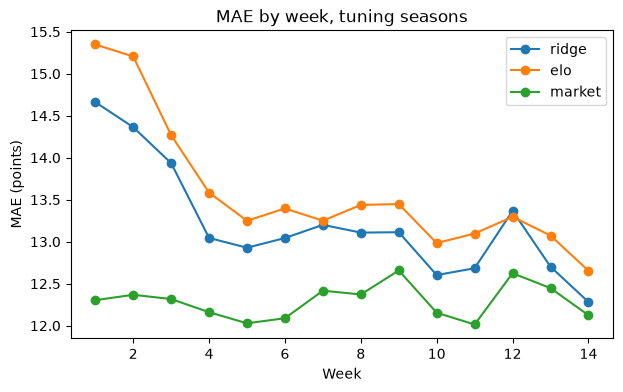

In [7]:
tuning = pred[pred["season"].isin(config.TUNING_SEASONS) & pred["market_spread"].notna()]
by_week = tuning[tuning["season_type"] == "regular"].groupby("week").apply(
    lambda b: pd.Series({
        "ridge": evaluate.mae(b["margin"], b["spread_pred"]),
        "elo": evaluate.mae(b["margin"], b["elo_spread"]),
        "market": evaluate.mae(b["margin"], b["market_spread"]),
    })
)
ax = by_week.loc[1:14].plot(marker="o", figsize=(7, 4), title="MAE by week, tuning seasons")
ax.set(xlabel="Week", ylabel="MAE (points)")

## 5. Ridge ratings vs. Elo ratings, end of 2024

Two different estimators of the same thing. They should agree broadly; the disagreements are where margin (ridge) and win/loss with an MOV multiplier (Elo) tell different stories.

correlation: 0.939


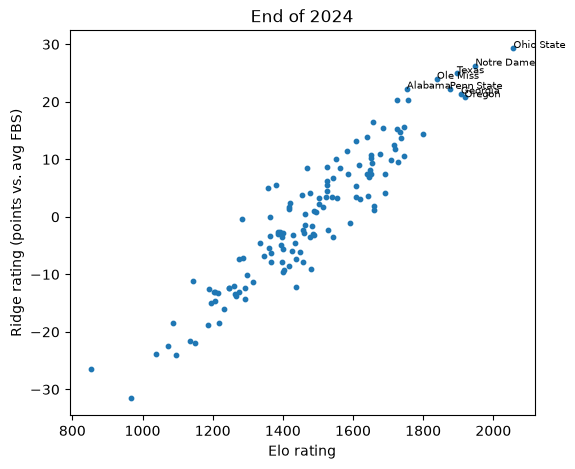

In [8]:
ridge_final = spread.final_ratings(games, params, 2024)
elo_final = elo.final_ratings(elo.run_elo(games[games["season"] <= 2024], elo.EloParams()))
both = ridge_final.merge(elo_final[["team", "rating"]], on="team", suffixes=("_ridge", "_elo"))
both = both[both["team"] != "FCS"]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(both["rating_elo"], both["rating_ridge"], s=10)
for _, row in both.head(8).iterrows():
    ax.annotate(row["team"], (row["rating_elo"], row["rating_ridge"]), fontsize=7)
ax.set(xlabel="Elo rating", ylabel="Ridge rating (points vs. avg FBS)", title="End of 2024")
print(f"correlation: {both['rating_elo'].corr(both['rating_ridge']):.3f}")